In [1]:
import marimo as mo

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [12]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

cols_categorical = "x4 x5 x10 Y".split()

df_train["Y"] = df_train["Y"].astype("category")

for df in (df_train, df_test):
    for _col in cols_categorical[:-1]:
        df[_col] = df[_col].astype("category")

    df.insert(10, column="x1a", value=(df.x1 >= 0).astype(np.int8).astype("category"))

✅ data loaded!


# model overview

- type - GAM logistic regression
- predictor selection method - manual

In [6]:
# https://pygam.readthedocs.io/en/latest/reference/_autosummary/pygam.pygam.LogisticGAM.html

from pygam import LogisticGAM, f, s, te

gam = LogisticGAM(
    s(1 - 1)
    + s(2 - 1)
    + s(3 - 1)
    + te(f(4 - 1), f(5 - 1), f(10 - 1), f(11 - 1))
    + s(6 - 1)
    + s(7 - 1)
    + s(8 - 1)
    + s(9 - 1)
).fit(df_train.iloc[:, df_train.columns != "Y"], df_train.Y)

In [7]:
gam.summary()

LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                    128.4039
Link Function:                        LogitLink Log Likelihood:                                 -7827.4246
Number of Samples:                        15000 AIC:                                            15911.6571
                                                AICc:                                           15913.9268
                                                UBRE:                                               3.0676
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.1174
Feature Function                  Lam

/tmp/nix-shell.aplRml/ipykernel_97531/3358381670.py:1: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  gam.summary()


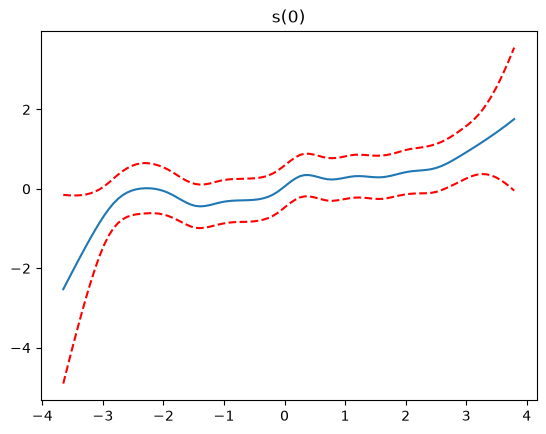

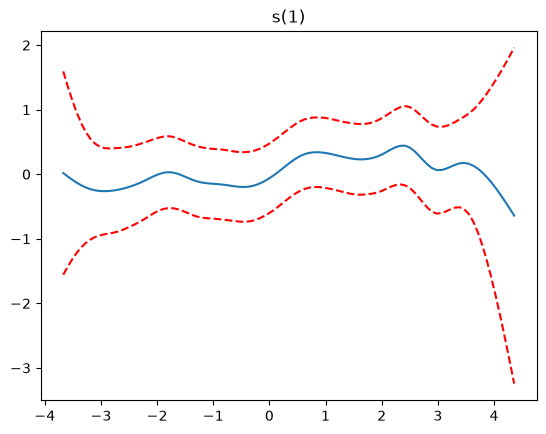

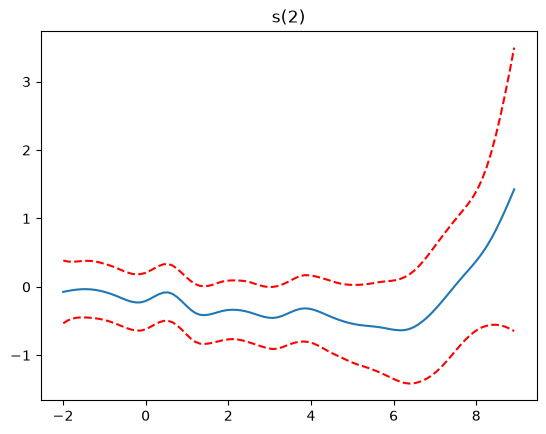

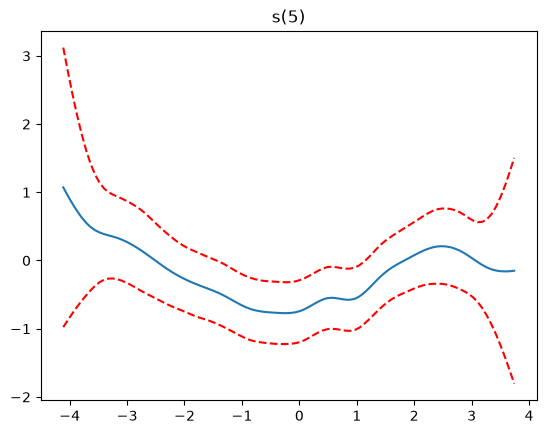

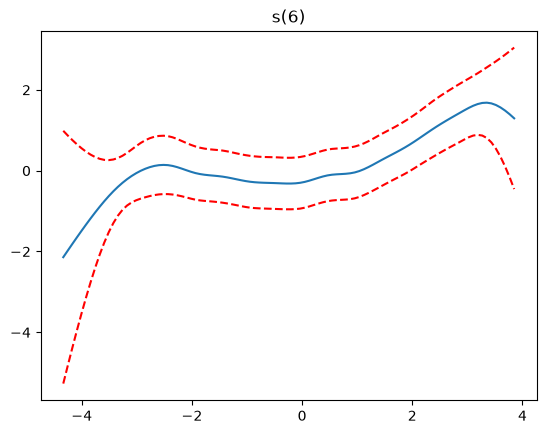

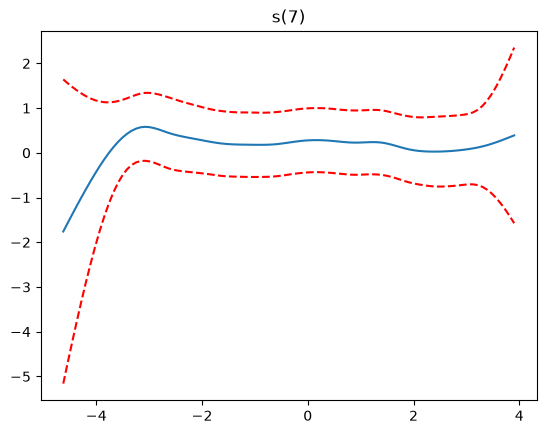

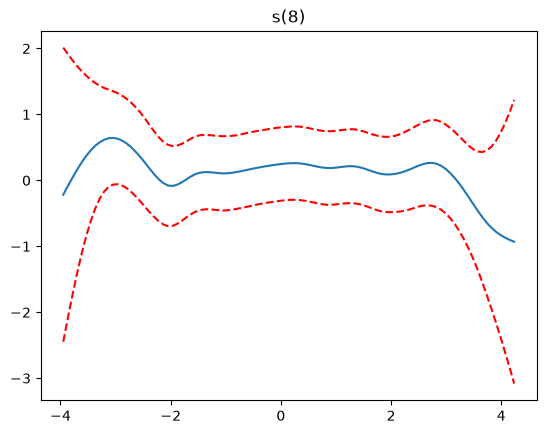

In [8]:
# https://pygam.readthedocs.io/en/latest/notebooks/quick_start.html#Partial-Dependence-Functions
for i, term in enumerate(gam.terms):
    if term.isintercept:
        continue
    if repr(term) == "te(3, 4, 9, 10)":
        continue

    XX = gam.generate_X_grid(term=i)
    pdep, confi = gam.partial_dependence(term=i, X=XX, width=0.95)

    plt.figure()
    plt.plot(XX[:, term.feature], pdep)
    plt.plot(XX[:, term.feature], confi, c="r", ls="--")
    plt.title(repr(term))
    plt.show()

now we remove the insignificant ones ($x_{10}, x_1, x_8, x_9$):

TODO use forward-backward-lasso to select parameters instead

In [9]:
prediction = gam.predict_proba(df_test)

prediction_probs = pd.Series(prediction, index=df_test.index)
prediction_probs.describe()

count    10000.000000
mean         0.276214
std          0.160889
min          0.008874
25%          0.130070
50%          0.263404
75%          0.393598
max          0.993914
dtype: float64

# model assessment

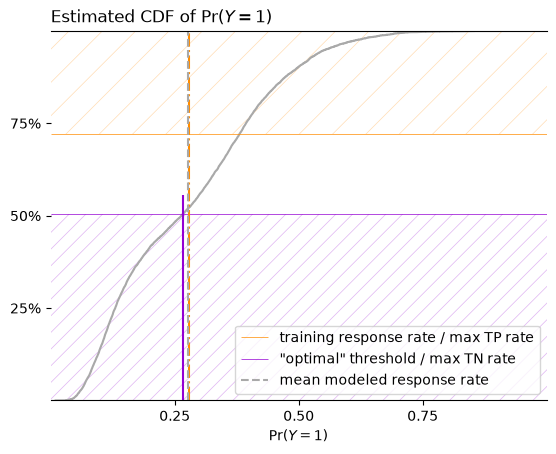

In [10]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

<Axes: title={'left': 'Comparison of F-scores'}>

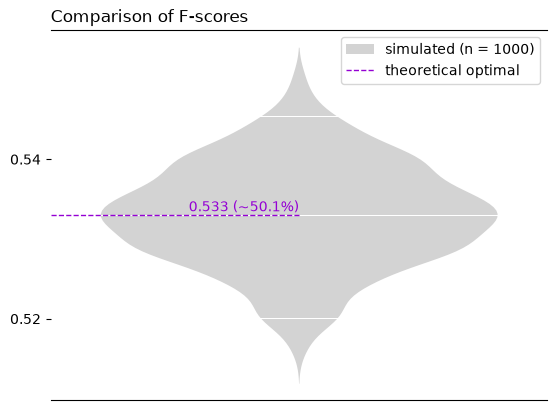

In [11]:
rng = np.random.default_rng(1)

th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng, 1000, prediction_probs, pos_prediction_count
    ),
    calculated=2 * threshold,
    reported=None,
)

## conclusion

- ~✅ the modeled average response rate (mostly) matches the training average
- the optimal F-score is somewhat low, compared to e.g. random forests

# make submission

In [12]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    0
15002    1
15003    1
15004    0
15005    0
        ..
24996    0
24997    1
24998    0
24999    0
25000    0
Length: 10000, dtype: int8

In [13]:
import os
import os.path
import pathlib

notebook_path = os.environ.get("JPY_SESSION_NAME")
submission_filepath = pathlib.Path(
    f"./submissions/{os.path.splitext(os.path.basename(notebook_path))[0]}.csv"
)
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model4_gam_binomial.csv
